# 03 · Decision Tree (handbook 3.5.1)
Entropy criterion; grid search over `min_samples_leaf`. Tuning metric: **macro-F1 on the validation set**
(the handbook's AUC is binary-only; macro-F1 weighs the rare A+ and G classes equally).

In [2]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

d = load_prepared()
x_train, x_val, x_test = d["x_train"], d["x_val"], d["x_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
feature_names = d["feature_names"]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
from sklearn.tree import DecisionTreeClassifier, plot_tree

train (114844, 1711) | val (28712, 1711) | test (35890, 1711)


## Tree without limits

In [3]:
dt = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(x_train, y_train)
print("Depth:", dt.get_depth(), "| leaves:", dt.get_n_leaves())
print("Validation macro-F1:", round(macro_f1(y_val, dt.predict(x_val)), 4))

Depth: 37 | leaves: 20527
Validation macro-F1: 0.6147


## Grid search over min_samples_leaf (coarse grid, handbook tip for large data)

1 0.6147
5 0.6104
10 0.6232
20 0.6309
50 0.6328
100 0.6204
200 0.6063
500 0.577
Optimal min_samples_leaf: 50


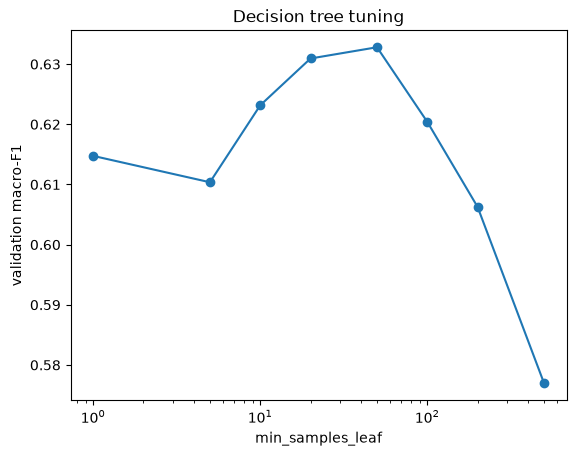

In [4]:
N = [1, 5, 10, 20, 50, 100, 200, 500]
f1_val = []
for n in N:
    m = DecisionTreeClassifier(criterion="entropy", min_samples_leaf=n, random_state=0).fit(x_train, y_train)
    f1_val.append(macro_f1(y_val, m.predict(x_val)))
    print(n, round(f1_val[-1], 4))

leaf_opt = N[int(np.argmax(f1_val))]
print("Optimal min_samples_leaf:", leaf_opt)
plt.plot(N, f1_val, marker="o"); plt.xscale("log")
plt.xlabel("min_samples_leaf"); plt.ylabel("validation macro-F1"); plt.title("Decision tree tuning")
plt.show()

## Final tree: evaluate on test and save

{'model': 'Decision Tree', 'accuracy': 0.6186, 'macro_F1': 0.629, 'ordinal_MAE': 0.5483, 'within_one': 0.8831, 'EFG_recall': 0.7818, 'AUC_ovr': 0.9225}


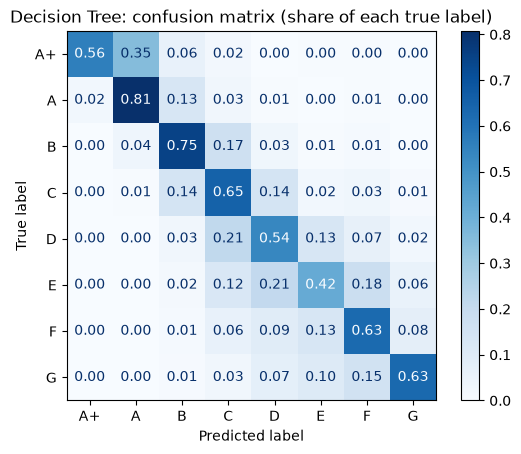

In [5]:
DT = DecisionTreeClassifier(criterion="entropy", min_samples_leaf=leaf_opt, random_state=0).fit(x_train, y_train)
evaluate("Decision Tree", DT, x_test, y_test)
save_model(DT, "DT")

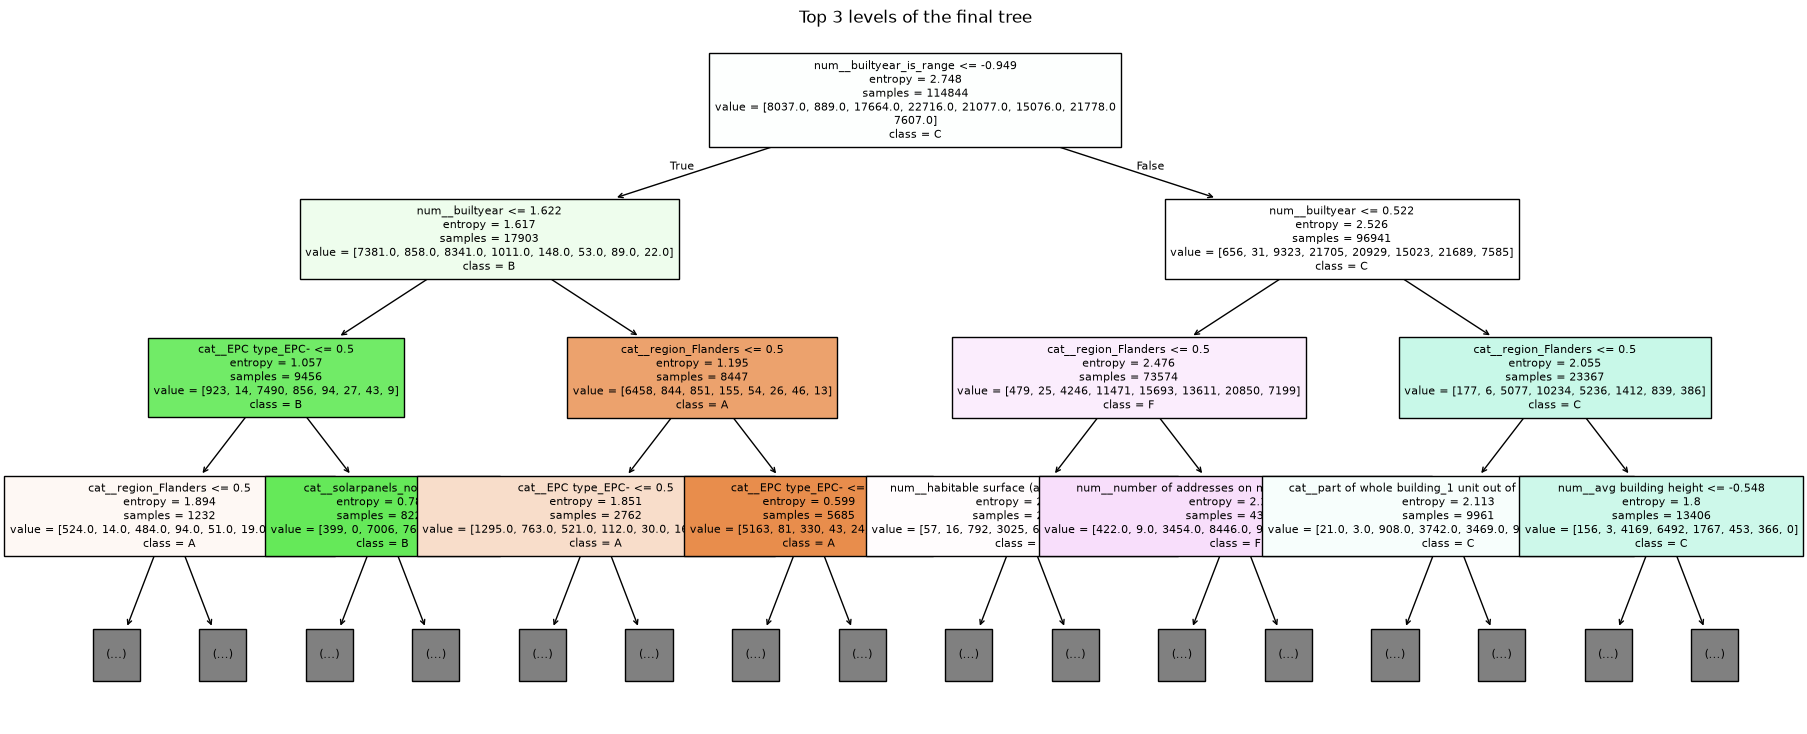

In [6]:
plt.figure(figsize=(22, 9))
plot_tree(DT, max_depth=3, feature_names=feature_names, class_names=list(DT.classes_), filled=True, fontsize=8)
plt.title("Top 3 levels of the final tree")
plt.show()